# **INTRODUCTION TO PANDAS**
---
<img src="Imperial_logo.png" align = "left" width=200>
 <br><br>
 
- Copyright (c) Antoine Jacquier, 2024. All rights reserved

- Author: Jack Jacquier <a.jacquier@imperial.ac.uk>

- Platform: Tested on Windows 10 with Python 3.9

 **Origins**
 
 `pandas` was originally developed by [Wes McKinney](https://wesmckinney.com) while at AQR Capital in 2007-2010.

# Introduction to DataFrames

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
%matplotlib inline

## Create a Dataframe with dates

We start by creating series of Gaussian distributed values.

In [2]:
N = 10000 ## size of the dataframe

In [3]:
xx = np.random.standard_normal((N, 5))
df = pd.DataFrame(xx)

In [4]:
type(df)

pandas.core.frame.DataFrame

In [5]:
df.head() ## Print the top five rows

,0,1,2,3,4
0,-1.409920,0.613840,0.710507,-1.315877,0.031919
1,-1.295015,0.444406,0.848619,-0.138499,1.374760
2,-0.134611,-0.539008,0.158218,-0.708859,0.595925
3,0.465705,0.689413,-1.600283,1.023047,0.065293
4,-0.311877,0.303217,-0.584629,-0.311421,2.332496


In [6]:
df.tail() ## Print the bottom five rows

,0,1,2,3,4
9995,-0.057542,0.286033,-0.248576,-0.048709,-0.470963
9996,0.947038,0.848968,-0.262843,1.555383,0.054336
9997,1.731236,0.373724,-0.105121,0.275268,0.042372
9998,-2.049401,-1.341610,-0.071370,-0.218253,0.408047
9999,-1.207485,0.606188,0.482426,-0.069078,1.037798


In [7]:
df.columns = ["Series 1", "Series 2", "Series 3", "Series 4", "Series 5"]
## Or more concisely:
#df.columns = ["Series %s" % i  for i in range(1,6)]
df.head()

,Series 1,Series 2,Series 3,Series 4,Series 5
0,-1.409920,0.613840,0.710507,-1.315877,0.031919
1,-1.295015,0.444406,0.848619,-0.138499,1.374760
2,-0.134611,-0.539008,0.158218,-0.708859,0.595925
3,0.465705,0.689413,-1.600283,1.023047,0.065293
4,-0.311877,0.303217,-0.584629,-0.311421,2.332496


Note that the index (first column on the left) has no real meaning here. 
However, in practice, thinking or each other column as time series, it may represent dates. 
We re-index the whole dataframe with this in mind.

#### Specifying a start date

In [8]:
startYear = '2018'
startMonth = '01'
startDay = '01'
startDate = startYear + "-" + startMonth + "-" + startDay ## string concatenation
print("Start date: ", startDate)

Start date:  2018-01-01


In [9]:
dates = pd.date_range(startDate, periods=N, freq="D")
df.index = dates
df.index.name = 'Date'
df.head()

,Series 1,Series 2,Series 3,Series 4,Series 5
Date,,,,,
2018-01-01,-1.409920,0.613840,0.710507,-1.315877,0.031919
2018-01-02,-1.295015,0.444406,0.848619,-0.138499,1.374760
2018-01-03,-0.134611,-0.539008,0.158218,-0.708859,0.595925
2018-01-04,0.465705,0.689413,-1.600283,1.023047,0.065293
2018-01-05,-0.311877,0.303217,-0.584629,-0.311421,2.332496


## Basic dataframe manipulations

In [15]:
df.keys()

Index(['Series 1', 'Series 2', 'Series 3', 'Series 4', 'Series 5'], dtype='object')

An Index is a `pandas` class for an immutable sequence, which is the basis for axes.

In [16]:
print('Names of columns:', [d for d in df.keys().values])
## similarly df.columns

Names of columns: ['Series 1', 'Series 2', 'Series 3', 'Series 4', 'Series 5']


Overview of the data

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 10000 entries, 2018-01-01 to 2045-05-18
Freq: D
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Series 1  10000 non-null  float64
 1   Series 2  10000 non-null  float64
 2   Series 3  10000 non-null  float64
 3   Series 4  10000 non-null  float64
 4   Series 5  10000 non-null  float64
dtypes: float64(5)
memory usage: 468.8 KB


Basic statistics

In [18]:
df.describe()

,Series 1,Series 2,Series 3,Series 4,Series 5
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,0.007207,0.003728,-0.004838,-0.003342,-0.008244
std,1.003506,0.990897,0.997257,1.006374,1.011910
min,-5.025025,-3.571951,-4.360186,-4.163449,-4.085065
25%,-0.670257,-0.664214,-0.689106,-0.678163,-0.693153
50%,0.013166,0.008462,-0.004206,-0.010430,-0.024791
75%,0.669022,0.684476,0.685878,0.665042,0.685233
max,3.648298,3.591156,4.126386,3.890992,3.811791


## Accessing elements from a dataframe

A  DataFrame may be indexed like an array, specifying the row and column number using .iloc (index location).
The location can be called either by the index number or by its name.

In [19]:
df.head()

,Series 1,Series 2,Series 3,Series 4,Series 5
Date,,,,,
2018-01-01,-1.409920,0.613840,0.710507,-1.315877,0.031919
2018-01-02,-1.295015,0.444406,0.848619,-0.138499,1.374760
2018-01-03,-0.134611,-0.539008,0.158218,-0.708859,0.595925
2018-01-04,0.465705,0.689413,-1.600283,1.023047,0.065293
2018-01-05,-0.311877,0.303217,-0.584629,-0.311421,2.332496


In [20]:
print("First row, second column: ", df.iloc[0, 1], " or ", df.loc[startDate, 'Series 2'])

First row, second column:  0.6138397451901776  or  0.6138397451901776


In [21]:
myRow = df.iloc[2,:]
print(myRow)
print("Type: ", type(myRow))

Series 1   -0.134611
Series 2   -0.539008
Series 3    0.158218
Series 4   -0.708859
Series 5    0.595925
Name: 2018-01-03 00:00:00, dtype: float64
Type:  <class 'pandas.core.series.Series'>


Equivalently:

In [22]:
myRow = df.loc['2018-01-03']
print(myRow, type(myRow))

Series 1   -0.134611
Series 2   -0.539008
Series 3    0.158218
Series 4   -0.708859
Series 5    0.595925
Name: 2018-01-03 00:00:00, dtype: float64 <class 'pandas.core.series.Series'>


In [23]:
print("Accessing elements by slicing over columns: ")
print(df.iloc[0, 1:3])
print(type(df.iloc[0, 1:3]))

Accessing elements by slicing over columns: 
Series 2    0.613840
Series 3    0.710507
Name: 2018-01-01 00:00:00, dtype: float64
<class 'pandas.core.series.Series'>


In [24]:
print("Accessing elements by slicing over rows: ")
print(df.iloc[10:14, 1])
print(type(df.iloc[10:14, 1]))

Accessing elements by slicing over rows: 
Date
2018-01-11    0.629613
2018-01-12   -0.971471
2018-01-13    1.126679
2018-01-14   -0.154585
Freq: D, Name: Series 2, dtype: float64
<class 'pandas.core.series.Series'>


In [25]:
print("Accessing elements by slicing over boths: ")
print(df.iloc[10:14, 1:3])
print(type(df.iloc[10:14, 1:3]))

Accessing elements by slicing over boths: 
            Series 2  Series 3
Date                          
2018-01-11  0.629613 -1.482569
2018-01-12 -0.971471  1.882946
2018-01-13  1.126679 -0.041839
2018-01-14 -0.154585  0.495407
<class 'pandas.core.frame.DataFrame'>


Question: What are the types of the following objects:
- df.iloc[2]
- df.iloc[2].values
- [d for d in df.iloc[2]]

In [26]:
print(type(df.iloc[2]))
print(type(df.iloc[2].values))
print(type([d for d in df.iloc[2]]))

<class 'pandas.core.series.Series'>
<class 'numpy.ndarray'>
<class 'list'>


### `.at` and `.iat`

These two commands are very similar to `.loc` and `.iloc`, and are actually faster, but slicing is not permitted.

In [27]:
%timeit df.iloc[10, 2]
%timeit df.iat[10, 2]

28.9 μs ± 1.67 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
21.4 μs ± 552 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [28]:
df.iat[10, 2:4]

ValueError: iAt based indexing can only have integer indexers

### Extract elements with conditions

In [29]:
mySeriesName = "Series 2"
df[df[mySeriesName] > 3.4]

,Series 1,Series 2,Series 3,Series 4,Series 5
Date,,,,,
2024-02-02,0.929918,3.466258,-0.109858,-0.613788,-1.570491
2030-06-06,-0.123298,3.424028,-1.668287,0.338966,-0.021790
2041-06-05,1.780795,3.591156,-1.874193,-0.322644,0.826612


Note that the series `df` has not been modified. Only a copy has been printed!!

In [30]:
mySeries =  df[mySeriesName][df[mySeriesName] > 3.4]
mySeries

Date
2024-02-02    3.466258
2030-06-06    3.424028
2041-06-05    3.591156
Name: Series 2, dtype: float64

We can return the series only as a list:

In [31]:
print(mySeries.values)

[3.46625797 3.424028   3.59115609]


### User-defined functions

In [32]:
df = df
df.head()

,Series 1,Series 2,Series 3,Series 4,Series 5
Date,,,,,
2018-01-01,-1.409920,0.613840,0.710507,-1.315877,0.031919
2018-01-02,-1.295015,0.444406,0.848619,-0.138499,1.374760
2018-01-03,-0.134611,-0.539008,0.158218,-0.708859,0.595925
2018-01-04,0.465705,0.689413,-1.600283,1.023047,0.065293
2018-01-05,-0.311877,0.303217,-0.584629,-0.311421,2.332496


Here, the original dataframe has been modified!

In [33]:
def myFunction(x, param):
    return x - param

df[mySeriesName] = df[mySeriesName].apply(myFunction, args=(10,))
df.head()

,Series 1,Series 2,Series 3,Series 4,Series 5
Date,,,,,
2018-01-01,-1.409920,-9.386160,0.710507,-1.315877,0.031919
2018-01-02,-1.295015,-9.555594,0.848619,-0.138499,1.374760
2018-01-03,-0.134611,-10.539008,0.158218,-0.708859,0.595925
2018-01-04,0.465705,-9.310587,-1.600283,1.023047,0.065293
2018-01-05,-0.311877,-9.696783,-0.584629,-0.311421,2.332496


## Numpy on dataframe

This is where the power of the DataFrame comes into the picture, namely that operations need to be performed element by element, 
but apply to a whole series (column) at once.

In [34]:
myIndex = input("Series index")

Series index 1


In [35]:
ser = 'Series ' + myIndex
print('Maximum on the first Series:', df[ser].max())
print('Date (index) where this maximum is attained:', df[ser].argmax()) ## deprecated
print('Date where this maximum is attained:', df[ser].idxmax(), df.index[df[ser].argmax()])
print('Mean of the first series:', df[ser].mean())

Maximum on the first Series: 3.648297735487979
Date (index) where this maximum is attained: 169
Date where this maximum is attained: 2018-06-19 00:00:00 2018-06-19 00:00:00
Mean of the first series: 0.0072067806744981165


We can also obtain general results about the whole dataframe / each series in the dataframe:

In [36]:
df.mean()

Series 1    0.007207
Series 2   -9.996272
Series 3   -0.004838
Series 4   -0.003342
Series 5   -0.008244
dtype: float64

## Plotting Dataframes

##### Plot all the time series

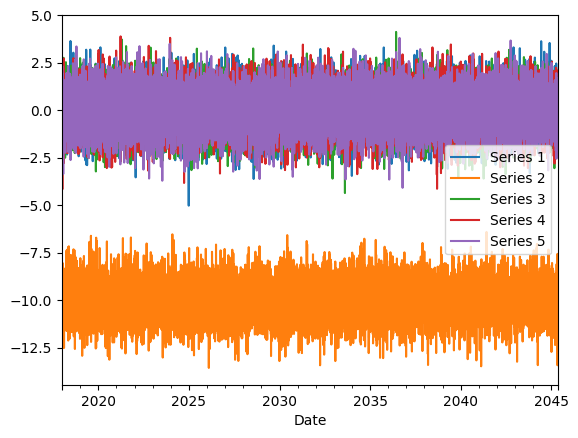

In [37]:
df.plot();

**WHAT IS WRONG ABOUT THE PLOT?**

##### Plot one column at a time

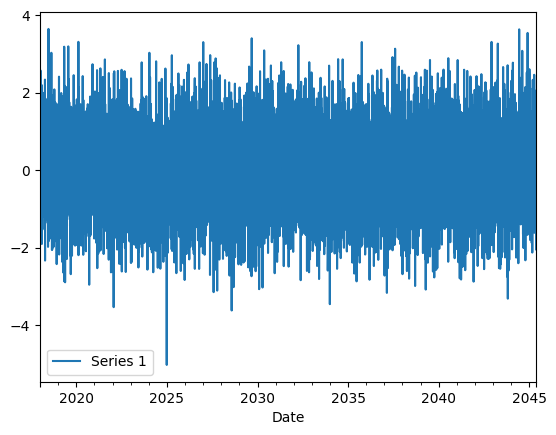

In [38]:
df[ser].plot(legend=ser);

##### Changing the type of plots

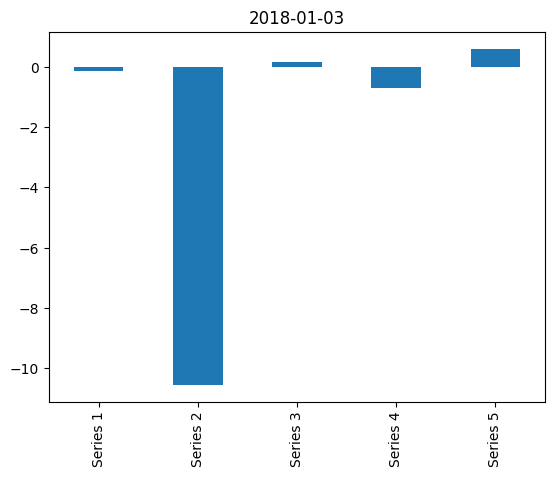

In [39]:
datePlot = '2018-01-03'
df.loc[datePlot].plot(kind='bar', title=datePlot); ## for one particular day

## Sorting DataFrames

In [40]:
print('Data sorted by ' + ser)
df.sort_values(by=ser).head()

Data sorted by Series 1


,Series 1,Series 2,Series 3,Series 4,Series 5
Date,,,,,
2024-12-28,-5.025025,-9.560197,-0.725223,1.227968,0.139814
2028-07-29,-3.619901,-9.486515,-0.013800,1.846570,-1.083493
2022-01-23,-3.534064,-8.720005,-1.076556,0.862209,-0.150886
2033-12-29,-3.456794,-9.569810,0.052564,0.076062,1.108506
2043-10-26,-3.314913,-10.881533,0.279867,0.491876,0.147210


*WARNING: the dataframe df itself has remained unchanged though...*

In [41]:
df.head()

,Series 1,Series 2,Series 3,Series 4,Series 5
Date,,,,,
2018-01-01,-1.409920,-9.386160,0.710507,-1.315877,0.031919
2018-01-02,-1.295015,-9.555594,0.848619,-0.138499,1.374760
2018-01-03,-0.134611,-10.539008,0.158218,-0.708859,0.595925
2018-01-04,0.465705,-9.310587,-1.600283,1.023047,0.065293
2018-01-05,-0.311877,-9.696783,-0.584629,-0.311421,2.332496


## Renaming columns

In [42]:
df.rename(columns={'Series 1': 'SPX', 
                   'Series 2': 'DAX', 
                   'Series 3': 'GOOGL', 
                   'Series 4': 'AAPL', 
                   'Series 5': 'VIX'}, inplace=True)
df.head()

,SPX,DAX,GOOGL,AAPL,VIX
Date,,,,,
2018-01-01,-1.409920,-9.386160,0.710507,-1.315877,0.031919
2018-01-02,-1.295015,-9.555594,0.848619,-0.138499,1.374760
2018-01-03,-0.134611,-10.539008,0.158218,-0.708859,0.595925
2018-01-04,0.465705,-9.310587,-1.600283,1.023047,0.065293
2018-01-05,-0.311877,-9.696783,-0.584629,-0.311421,2.332496


### A note on copies on slices....

In [43]:
df.head()

,SPX,DAX,GOOGL,AAPL,VIX
Date,,,,,
2018-01-01,-1.409920,-9.386160,0.710507,-1.315877,0.031919
2018-01-02,-1.295015,-9.555594,0.848619,-0.138499,1.374760
2018-01-03,-0.134611,-10.539008,0.158218,-0.708859,0.595925
2018-01-04,0.465705,-9.310587,-1.600283,1.023047,0.065293
2018-01-05,-0.311877,-9.696783,-0.584629,-0.311421,2.332496


In [44]:
val = df.iloc[1,0]
val

np.float64(-1.295014886524626)

In [45]:
df[df["SPX"] == val]["DAX"] = 0.
df

C:\cygwin64\tmp\ipykernel_6072\3746132791.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[df["SPX"] == val]["DAX"] = 0.


,SPX,DAX,GOOGL,AAPL,VIX
Date,,,,,
2018-01-01,-1.409920,-9.386160,0.710507,-1.315877,0.031919
2018-01-02,-1.295015,-9.555594,0.848619,-0.138499,1.374760
2018-01-03,-0.134611,-10.539008,0.158218,-0.708859,0.595925
2018-01-04,0.465705,-9.310587,-1.600283,1.023047,0.065293
2018-01-05,-0.311877,-9.696783,-0.584629,-0.311421,2.332496
...,...,...,...,...,...
2045-05-14,-0.057542,-9.713967,-0.248576,-0.048709,-0.470963
2045-05-15,0.947038,-9.151032,-0.262843,1.555383,0.054336
2045-05-16,1.731236,-9.626276,-0.105121,0.275268,0.042372


In [46]:
df.loc[df["SPX"] == val, "DAX"] = 0.
df

,SPX,DAX,GOOGL,AAPL,VIX
Date,,,,,
2018-01-01,-1.409920,-9.386160,0.710507,-1.315877,0.031919
2018-01-02,-1.295015,0.000000,0.848619,-0.138499,1.374760
2018-01-03,-0.134611,-10.539008,0.158218,-0.708859,0.595925
2018-01-04,0.465705,-9.310587,-1.600283,1.023047,0.065293
2018-01-05,-0.311877,-9.696783,-0.584629,-0.311421,2.332496
...,...,...,...,...,...
2045-05-14,-0.057542,-9.713967,-0.248576,-0.048709,-0.470963
2045-05-15,0.947038,-9.151032,-0.262843,1.555383,0.054336
2045-05-16,1.731236,-9.626276,-0.105121,0.275268,0.042372


# Working with real data

## Financial data from Yahoo Finance

In [1]:
! pip install pandas_datareader


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
pd.core.common.is_list_like = pd.api.types.is_list_like
import pandas_datareader as web
from pandas_datareader import data as pdr
from datetime import datetime
import yfinance as yf
#import yahoo_fin.stock_info as si

In [6]:
ticker = "AAPL"
#df_share = si.get_data(ticker, start_date = "01/01/1980", end_date = "01/31/2024")
#df_share.head()

# download apple data for a specific daterange
df_share = yf.download("AAPL", start="2000-01-01", end="2024-01-01")
df_share.head()

C:\Users\Dell\OneDrive\Documents\TomDocuments\PythonProjects\Math70112\20261027\MATH_70112\math_70112_venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\Dell\OneDrive\Documents\TomDocuments\PythonProjects\Math70112\20261027\MATH_70112\math_70112_venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\Dell\OneDrive\Documents\TomDocuments\PythonProjects\Math70112\20261027\MATH_70112\math_70112_venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2000-01-03,0.837002,0.841208,0.760359,0.784193,535796800
2000-01-04,0.766435,0.827188,0.756620,0.809430,512377600
2000-01-05,0.777650,0.826721,0.770173,0.775781,778321600
2000-01-06,0.710353,0.800082,0.710353,0.793540,767972800
2000-01-07,0.744002,0.755218,0.714093,0.721570,460734400


In [7]:
df_share.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 6037 entries, 2000-01-03 to 2023-12-29
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   6037 non-null   float64
 1   (High, AAPL)    6037 non-null   float64
 2   (Low, AAPL)     6037 non-null   float64
 3   (Open, AAPL)    6037 non-null   float64
 4   (Volume, AAPL)  6037 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 283.0 KB


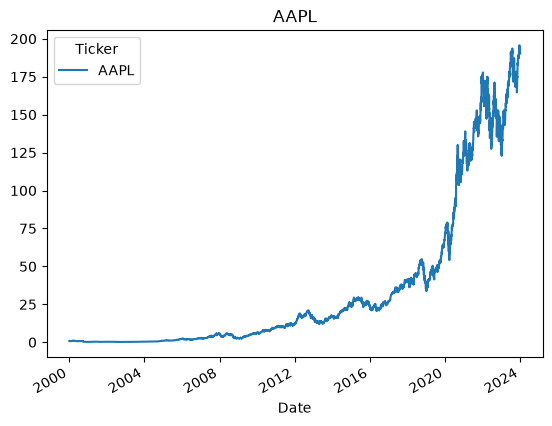

In [11]:
df_share["Close"].plot(title=ticker)
plt.show()

## Economics Data from FRED

In [12]:
from datetime import date
series_code = 'DGS10' # 10-year Treasury Rate
data_source = 'fred' # FED Economic Data Service
start = date(1962, 1, 1)
myData = pdr.DataReader(series_code, data_source, start)

In [13]:
myData.head()

,DGS10
DATE,
1962-01-02,4.06
1962-01-03,4.03
1962-01-04,3.99
1962-01-05,4.02
1962-01-08,4.03


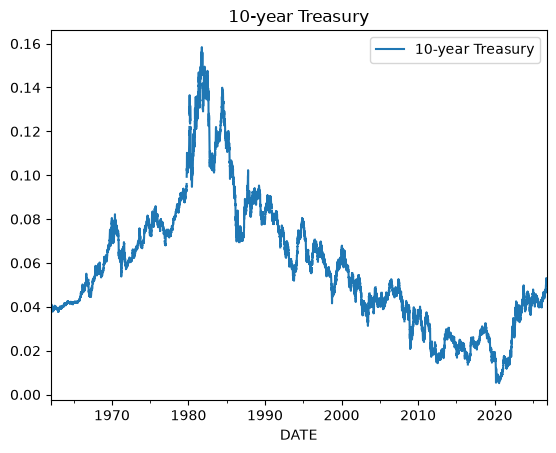

In [14]:
myData = myData / 100.
series_name = '10-year Treasury'
myData = myData.rename(columns={series_code: series_name})
myData.plot(title=series_name)
plt.show() 

## Analysing real data

In [15]:
#ticker = "^GSPC" ## S&P500 
#spx = si.get_data(ticker, start_date = "01/01/1980", end_date = "01/31/2024")
#spx.info()

# download apple data for a specific daterange
spx = yf.download("^GSPC", start="2020-01-01", end="2024-01-01")
spx.head()

C:\Users\Dell\OneDrive\Documents\TomDocuments\PythonProjects\Math70112\20261027\MATH_70112\math_70112_venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\Dell\OneDrive\Documents\TomDocuments\PythonProjects\Math70112\20261027\MATH_70112\math_70112_venv\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
C:\Users\Dell\OneDrive\Documents\TomDocuments\PythonProjects\Math70112\20261027\MATH_70112\math_70112_venv\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and

Price,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,
2020-01-02,3257.850098,3258.139893,3235.530029,3244.669922,3459930000
2020-01-03,3234.850098,3246.149902,3222.340088,3226.360107,3484700000
2020-01-06,3246.280029,3246.840088,3214.639893,3217.550049,3702460000
2020-01-07,3237.179932,3244.909912,3232.429932,3241.860107,3435910000
2020-01-08,3253.050049,3267.070068,3236.669922,3238.590088,3726840000


In [16]:
spx.head()

Price,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,
2020-01-02,3257.850098,3258.139893,3235.530029,3244.669922,3459930000
2020-01-03,3234.850098,3246.149902,3222.340088,3226.360107,3484700000
2020-01-06,3246.280029,3246.840088,3214.639893,3217.550049,3702460000
2020-01-07,3237.179932,3244.909912,3232.429932,3241.860107,3435910000
2020-01-08,3253.050049,3267.070068,3236.669922,3238.590088,3726840000


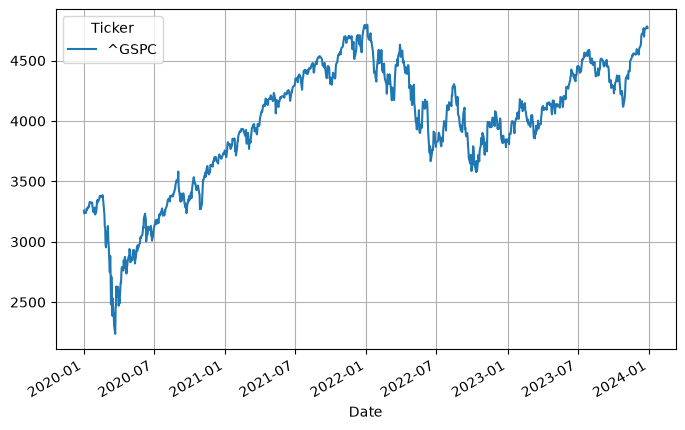

In [17]:
spx['Close'].plot(figsize=(8, 5), grid=True);

### A quick note on computation time -- computing daily returns

In [18]:
len(spx)

1006

In [20]:
%%time
spx['ReturnsLoop'] = 0.
for i in range(1, len(spx)):
    spx['ReturnsLoop'][i] = np.log(spx['Close'][i] / spx['Close'][i - 1])

CPU times: total: 0 ns
Wall time: 2.71 ms


KeyError: 1

In [21]:
spx[['Close', 'ReturnsLoop']].head()

Price,Close,ReturnsLoop
Ticker,^GSPC,
Date,,
2020-01-02,3257.850098,0.0
2020-01-03,3234.850098,0.0
2020-01-06,3246.280029,0.0
2020-01-07,3237.179932,0.0
2020-01-08,3253.050049,0.0


In [22]:
%time spx['Returns'] = np.log(spx['Close'] / spx['Close'].shift(1))
spx[['Close', 'Returns']].head()

CPU times: total: 15.6 ms
Wall time: 4.05 ms


<timed exec>:1: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.


Price,Close,Returns
Ticker,^GSPC,
Date,,
2020-01-02,3257.850098,NaN
2020-01-03,3234.850098,-0.007085
2020-01-06,3246.280029,0.003527
2020-01-07,3237.179932,-0.002807
2020-01-08,3253.050049,0.004890


In [23]:
del spx['ReturnsLoop']

In [24]:
spx = spx.dropna()
spx.head()

Price,Close,High,Low,Open,Volume,Returns
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,
Date,,,,,,
2020-01-03,3234.850098,3246.149902,3222.340088,3226.360107,3484700000,-0.007085
2020-01-06,3246.280029,3246.840088,3214.639893,3217.550049,3702460000,0.003527
2020-01-07,3237.179932,3244.909912,3232.429932,3241.860107,3435910000,-0.002807
2020-01-08,3253.050049,3267.070068,3236.669922,3238.590088,3726840000,0.004890
2020-01-09,3274.699951,3275.580078,3263.669922,3266.030029,3641230000,0.006633


In [25]:
val = df.iloc[0,0]
val

NameError: name 'df' is not defined

In [ ]:
df[df['SPX'] == val]['DAX'] = 0.
df.head()

In [ ]:
df.loc[df['SPX'] == val, 'DAX'] = 0.
df.head()

**WHAT IS THE PROBLEM?**

### Data analysis

In [ ]:
spx[['close', 'Returns']].plot(subplots=True, style='b',figsize=(8, 6));

**Remarks:**
- Volatility clustering
- Leverage effect

### Moving averages

In [27]:
n1, n2 = 24, 252
MA1, MA2 = 'MA' + str(n1) + 'd', 'MA' + str(n2) + 'd'
spx[MA1] = spx['Close'].rolling(window=n1, center = False).mean()
spx[MA2] = spx['Close'].rolling(window=n2, center = False).mean()
spx.tail()

C:\cygwin64\tmp\ipykernel_30256\3608207413.py:3: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  spx[MA1] = spx['Close'].rolling(window=n1, center = False).mean()
C:\cygwin64\tmp\ipykernel_30256\3608207413.py:4: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  spx[MA2] = spx['Close'].rolling(window=n2, center = False).mean()


Price,Close,High,Low,Open,Volume,Returns,MA24d,MA252d
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,,,
Date,,,,,,,,
2023-12-22,4754.629883,4772.939941,4736.770020,4753.919922,3046770000,0.001659,4625.697896,4265.044879
2023-12-26,4774.750000,4784.720215,4758.450195,4758.859863,2513910000,0.004223,4635.171651,4268.824086
2023-12-27,4781.580078,4785.390137,4768.899902,4773.450195,2748450000,0.001429,4645.312907,4272.541388
2023-12-28,4783.350098,4793.299805,4780.979980,4786.439941,2698860000,0.000370,4654.759989,4276.327499
2023-12-29,4769.830078,4788.430176,4751.990234,4782.879883,3126060000,-0.002830,4663.530416,4280.242619


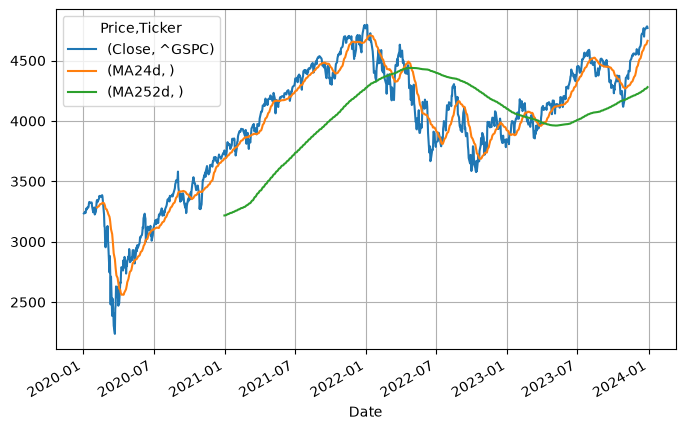

In [28]:
spx[['Close', MA1, MA2]].plot(figsize=(8, 5), grid=True);

In [29]:
spx['MovingReturnsVol'] = spx['Returns'].rolling(window=252).std() * np.sqrt(252.)

C:\cygwin64\tmp\ipykernel_30256\3019002948.py:1: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  spx['MovingReturnsVol'] = spx['Returns'].rolling(window=252).std() * np.sqrt(252.)


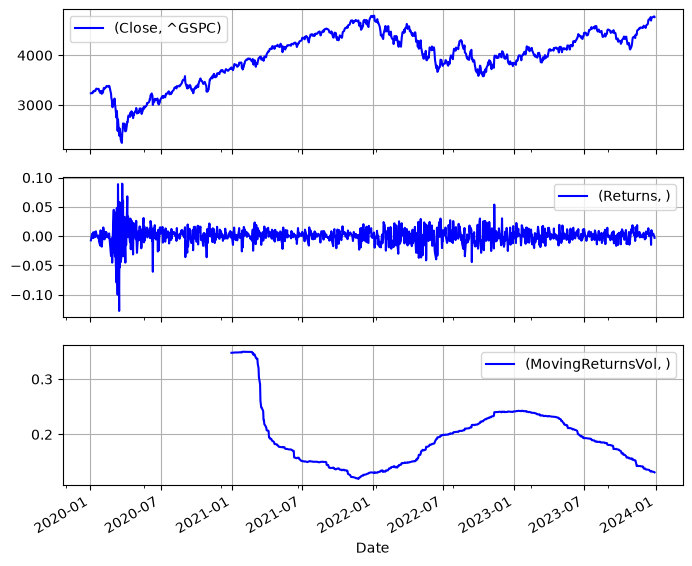

In [31]:
spx[['Close', 'Returns', 'MovingReturnsVol']].plot(subplots=True, style='b',figsize=(8, 7), grid=True);

# The `groupby` command

In [32]:
import pandas as pd

df = pd.read_excel('Class.xlsx')
df.head()

,Name,Grade,Nationality,Gender
0,John,81.791817,China,M
1,Joe,96.101421,UK,M
2,Jack,96.466640,France,F
3,Ben,93.981908,US,M
4,Cynthia,53.858965,Japan,M


In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         35 non-null     str    
 1   Grade        35 non-null     float64
 2   Nationality  35 non-null     str    
 3   Gender       35 non-null     str    
dtypes: float64(1), str(3)
memory usage: 1.2 KB


In [34]:
df["Grade"].mean()

np.float64(75.78772944884835)

In [35]:
df["Grade"].sum()# / len(df.index)

np.float64(2652.5705307096923)

In [36]:
df.groupby(['Nationality']).agg({'Grade': 'mean'})

,Grade
Nationality,
Cambodia,73.970554
China,72.109283
France,73.727389
German,78.613666
Japan,71.400133
Korea,76.892591
UK,74.029734
US,85.262760
Vietnam,72.649608


In [37]:
df.groupby(['Nationality']).agg({'Grade': 'sum'})

,Grade
Nationality,
Cambodia,147.941108
China,576.874264
France,147.454778
German,157.227331
Japan,357.000665
Korea,153.785183
UK,370.148668
US,596.839317
Vietnam,145.299216


In [38]:
df.groupby(['Nationality', 'Gender']).agg({'Grade': 'mean'})#.sum()

Grade
Nationality Gender           
Cambodia    F       55.248696
            M       92.692412
China       F       63.916977
            M       74.840051
France      F       73.727389
German      F       68.975979
            M       88.251352
Japan       M       71.400133
Korea       M       76.892591
UK          F       68.511812
            M       96.101421
US          F       78.429933
            M       87.995890
Vietnam     F       66.581475
            M       78.717741

**WHAT IS HAPPENING????**

# Merge, join, concatenate data -- an example with the MTA database

NYC map: https://www.google.com/maps/place/New+York,+NY,+USA/@40.6976684,-74.2605634,10z/data=!3m1!4b1!4m5!3m4!1s0x89c24fa5d33f083b:0xc80b8f06e177fe62!8m2!3d40.7127753!4d-74.0059728


Data: http://web.mta.info/developers/turnstile.html



### Importing and looking at the data

In [ ]:
import datetime as dt
import pandas as pd

In [ ]:
url  = r'http://web.mta.info/developers/data/nyct/turnstile/turnstile_180825.txt'
df = pd.read_csv(url)#, index_col=0, header=0, parse_dates=True)

In [ ]:
df.info()

In [ ]:
df.head()

In [ ]:
#!pip install xlrd

In [ ]:
url  = r'http://web.mta.info/developers/resources/nyct/turnstile/Remote-Booth-Station.xls'
infoStations = pd.read_excel(url)#, index_col=0, header=0, parse_dates=True)
infoStations.head()

### Cleaning the data

In [ ]:
df['ENTRIES'].max()

In [ ]:
df['EXITS'].max()

In [ ]:
df.keys()

In [ ]:
df.columns = ['ca', 'unit', 'scp', 'station', 'linename', 'division', 'date','time', 'desc', 'entries','exits']

In [ ]:
df['exits'].max()

In [ ]:
#df["date"] = pd.to_datetime(df["date"] + " " + df["time"])
df["date"] = pd.to_datetime(df["date"])
df.head()

### Counting daily traffic using `groupbby`

In [ ]:
df_entries = df.groupby(['station','ca','unit','scp','date']).entries.max() - df.groupby(['station','ca','unit','scp','date']).entries.min()
df_exits = df.groupby(['station','ca','unit','scp','date']).exits.max() - df.groupby(['station','ca','unit','scp','date']).exits.min()
print("Types: ", type(df_entries), type(df_exits))

In [ ]:
df_entries[:10]

We are now going to merge `df_entries` and `df_exits`. However, they need to have the same index.
https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html

In [ ]:
df_entries_flat = df_entries.reset_index()
df_exits_flat = df_exits.reset_index()

In [ ]:
df_entries_flat.head()

In [ ]:
df_traffic = pd.merge(df_entries_flat, df_exits_flat, how='outer')
df_traffic.head()

In [ ]:
df_traffic['day'] = df_traffic['date'].dt.day_name()
df_traffic['traffic'] = df_traffic['entries'] + df_traffic['exits']

In [ ]:
df_traffic.head()

In [ ]:
#df_traffic[["entries", "exits"]].hist();
df_traffic[["traffic"]].hist();

In [ ]:
thresholdMax = 25000

df_traffic = df_traffic[df_traffic["traffic"] < thresholdMax]
#df_traffic = df_traffic[df_traffic["traffic"] > thresholdMax]
df_traffic["logtraffic"] = np.log(np.abs(np.maximum(df_traffic["traffic"], 1E-3)))

In [ ]:
df_traffic["logtraffic"].hist();

Final steps

In [ ]:
df_station = df_traffic.groupby(['station','date','day']).sum().reset_index()
df_station.head()

### What happens at Penn station?

In [ ]:
df_station["station"].unique()

In [ ]:
df_Penn = df_station[df_station["station"] == "42 ST-PORT AUTH"]
df_Penn
df_Penn.plot.bar(x="day", y="traffic");

### Exercise

- What are the 3 busiest stations on average?
- What is the traffic distribution over the week?
- What are the busiest stations on weekends and on weekdays?

### Exercise

Write a script that imports each weekly file http://web.mta.info/developers/turnstile.html and merges them.

# Common issues

In [ ]:
xx = [2, 4, 6, '8']
df = pd.DataFrame(xx)
df.columns = ["X"]
df.head()

In [ ]:
df["Mult"] = 2.*df["X"]

In [ ]:
df.info()

In [ ]:
df['X'] = pd.to_numeric(df['X'])
df["Mult"] = 2.*df["X"]

In [ ]:
df.info()

In [ ]:
df.head()

### Working with copies

In [ ]:
N = 5
xx = np.random.standard_normal((N, 5))
df = pd.DataFrame(xx)
df.head()

In [ ]:
df2 = df ### same as df.copy(deep=False)
df3 = df.copy(deep=True)

In [ ]:
i,j = 0,1
df.iat[i,j] = 2.
print(df.iat[i,j], df2.iat[i,j])

In [ ]:
i,j = 0,1
df3.iat[i,j] = 5.
print(df.iat[i,j], df3.iat[i,j])

### Filling the void

In [ ]:
df = pd.read_csv("../Data files/eurgbp-1m.csv", sep=";")#,header = None)
df.columns=["Date", "Time", "Bid", "Ask", "na", "na2", "na3"]
#df["DateTime"] = df["Date"] + df["Time"]
df = df.drop(columns=['na', 'na2', 'na3'])
df.head()

**Exercise:** Create a dataframe with one value for the bid and one value for the ask for each day.
For example, using the maximum value of the day.

In [ ]:
import random
chosenDay = df.iloc[random.choice(range(len(df))), 0]
print("Chosen day: ", chosenDay)

In [ ]:
oneDay = df[df["Date"] == chosenDay]
oneDay.set_index("Time", inplace=True)
del oneDay["Date"]
oneDay.plot(title="eurgbp on " + chosenDay);
oneDay.head()

In [ ]:
nbMissingValues = len(oneDay)//3
N = len(oneDay)
listMissingValues = random.choices(range(N), k=nbMissingValues)
for l in listMissingValues:
    oneDay.iat[l, 0] = np.log(-1.)

In [ ]:
oneDay.head()

In [ ]:
oneDay["Bid"].plot()

How do we fill the gaps? 
- `dropna`?
- interpolation? But which one?

In [ ]:
oneDay["Bid"].interpolate(method='linear', axis=0).plot();

# Extra: Combining DataFrames and creating signals

In [ ]:
import yahoo_fin.stock_info as si

aapl = si.get_data("AAPL", start_date = "01/01/1980", end_date = "01/31/2024")
coke = si.get_data("COKE", start_date = "01/01/1980", end_date = "01/31/2024")

In [ ]:
aapl.tail()

In [ ]:
coke.tail()

In [ ]:
df = pd.merge(coke, aapl, left_index=True, right_index=True)
df.head()

In [ ]:
df = pd.merge(coke["close"], aapl["close"], left_index=True, right_index=True)
df.columns = ["coke", "aapl"]
df.head()

In [ ]:
df.plot();

#### Normalised versions...

In [ ]:
coke = coke["close"] 
aapl = aapl["close"] 

In [ ]:
coke0 = coke.iloc[0]
aapl0 = aapl.iloc[0]

coke_norm = coke / coke0
aapl_norm = aapl / aapl0
df_norm = pd.merge(coke_norm, aapl_norm, left_index=True, right_index=True)
df_norm.columns = ["coke norm", "aapl norm"]
df_norm.plot();

In [ ]:
coke = si.get_data("COKE", start_date = "01/01/1980", end_date = "01/31/2024")

In [ ]:
coke["Returns"] = np.log(coke['close'] / coke['close'].shift(1))
coke['MovingVol'] = coke['Returns'].rolling(window=252).std() * np.sqrt(252.)
coke = coke[["close", "Returns", "MovingVol"]]
coke = coke.dropna()
coke["MovingVol"].plot(title="Moving vol");

In [ ]:
maxVolAllowed = 0.4
coke.loc[coke['MovingVol'] > maxVolAllowed, 'Signal'] = 0.6#coke["MovingVol"].max()
coke[["Signal", "MovingVol"]].plot().legend(loc=3);

# WARNINGS: Data inconsistencies

- Missing data
- NaN, -1, ...
- Date format
- Blank spaces
- Formats: Int, float, ...